# Inspect processed Zarr datasets

Find the processed Zarr stores, inspect their xarray schemas and metadata, then load only a small sample. This notebook does not modify the data.

In [2]:
from pathlib import Path
import xarray as xr

def find_repo_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'data/legacy_dataset/processed').is_dir():
            return path
    raise FileNotFoundError('Cannot locate data/legacy_dataset/processed')

REPO_ROOT = find_repo_root()
ZARR_DIR = REPO_ROOT / 'data' / 'legacy_dataset' / 'processed'
stores = sorted(p for p in ZARR_DIR.glob('*.zarr') if p.is_dir())
print(f'{len(stores)} Zarr stores in {ZARR_DIR}')
for path in stores:
    print(path.name)

4 Zarr stores in d:\Projects\reboot\data\legacy_dataset\processed
ocean_q1_2020.zarr
predictions_q1_2020.zarr
surface_2020Q1.zarr
thetao_2020Q1.zarr


In [3]:
def inspect_store(path):
    """Open a Zarr store and print its dimensions, variables, and attributes."""
    ds = xr.open_zarr(path, consolidated=None)
    print(f'\n## {path.name}')
    print('Dimensions:', dict(ds.sizes))
    print('Variables:')
    for name, var in ds.data_vars.items():
        print(f'  {name}: dims={var.dims}, shape={var.shape}, dtype={var.dtype}')
    print('Coordinates:')
    for name, coord in ds.coords.items():
        print(f'  {name}: dims={coord.dims}, shape={coord.shape}, dtype={coord.dtype}')
    print('Attributes:', dict(ds.attrs))
    return ds

datasets = {p.stem: inspect_store(p) for p in stores}
if not datasets:
    raise FileNotFoundError(f'No .zarr stores in {ZARR_DIR}')


## ocean_q1_2020.zarr
Dimensions: {'time': 91, 'latitude': 100, 'longitude': 240, 'depth': 15}
Variables:
  current_u: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  current_v: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  sla: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  sss: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  sst: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  thetao: dims=('time', 'depth', 'latitude', 'longitude'), shape=(91, 15, 100, 240), dtype=float32
  wind_u: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
  wind_v: dims=('time', 'latitude', 'longitude'), shape=(91, 100, 240), dtype=float32
Coordinates:
  depth: dims=('depth',), shape=(15,), dtype=float32
  latitude: dims=('latitude',), shape=(100,), dtype=float32
  longitude: dims=('longitude',), shape=(240,), dtype=float32
  time:

## Inspect a small sample

Choose a store and variable. The code selects the first index on non-spatial dimensions and at most 20 latitude/longitude values before computing.

In [3]:
STORE_NAME = next(iter(datasets))  # e.g. 'ocean_q1_2020'
ds = datasets[STORE_NAME]
display(ds)

VARIABLE_NAME = next(iter(ds.data_vars))  # change after reviewing the variable list
var = ds[VARIABLE_NAME]
spatial_names = {'lat', 'latitude', 'lon', 'longitude'}
indexers = {dim: (slice(0, 20) if dim.lower() in spatial_names else 0) for dim in var.dims}
sample = var.isel(indexers).compute()
print(f'{VARIABLE_NAME}: sample dims={sample.dims}, shape={sample.shape}')
display(sample)

<xarray.Dataset> Size: 192MB
Dimensions:    (time: 91, latitude: 100, longitude: 240, depth: 15)
Coordinates:
  * time       (time) datetime64[ns] 728B 2020-01-01 2020-01-02 ... 2020-03-31
  * latitude   (latitude) float32 400B 5.125 5.375 5.625 ... 29.38 29.62 29.88
  * longitude  (longitude) float32 960B 45.12 45.38 45.62 ... 104.4 104.6 104.9
  * depth      (depth) float32 60B 0.494 5.078 9.573 18.5 ... 541.1 643.6 902.3
Data variables:
    current_u  (time, latitude, longitude) float32 9MB dask.array<chunksize=(1, 100, 240), meta=np.ndarray>
    current_v  (time, latitude, longitude) float32 9MB dask.array<chunksize=(1, 100, 240), meta=np.ndarray>
    sla        (time, latitude, longitude) float32 9MB dask.array<chunksize=(23, 50, 120), meta=np.ndarray>
    sss        (time, latitude, longitude) float32 9MB dask.array<chunksize=(23, 50, 120), meta=np.ndarray>
    sst        (time, latitude, longitude) float32 9MB dask.array<chunksize=(23, 50, 120), meta=np.ndarray>
    thetao     (time, depth, latitude, longitude) float32 131MB dask.array<chunksize=(1, 15, 100, 240), meta=np.ndarray>
    wind_u     (time, latitude, longitude) float32 9MB dask.array<chunksize=(1, 100, 240), meta=np.ndarray>
    wind_v     (time, latitude, longitude) float32 9MB dask.array<chunksize=(1, 100, 240), meta=np.ndarray>

current_u: sample dims=('latitude', 'longitude'), shape=(20, 20)


<xarray.DataArray 'current_u' (latitude: 20, longitude: 20)> Size: 2kB
array([[        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
        -0.91459423, -0.85139036, -0.7193655 , -0.5473823 , -0.38927364],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan, -0.81322616, -0.7014827 , -0.55641407, -0.4120654 ],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan, -0.77706915, -0.683564  , -0.5723015 , -0.4445216 ],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan, -0.6349738 , -0.54358774, -0.43310103],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan, -0.5201929 , -0.44066215, -0.33932176],
...
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan],
       [        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan]],
      dtype=float32)
Coordinates:
  * latitude   (latitude) float32 80B 5.125 5.375 5.625 ... 9.375 9.625 9.875
  * longitude  (longitude) float32 80B 45.12 45.38 45.62 ... 49.38 49.62 49.88
    time       datetime64[ns] 8B 2020-01-01
Attributes:
    long_name:              zonal total surface current
    standard_name:          eastward_sea_water_velocity
    units:                  m s-1
    coverage_content_type:  modelResult
    valid_min:              -3.0
    valid_max:              3.0
    depth:                  15m
    comment:                Velocities are an average over the top 30m of the...
    source:                 SSH source: CMEMS SSALTO/DUACS SEALEVEL_GLO_PHY_L...

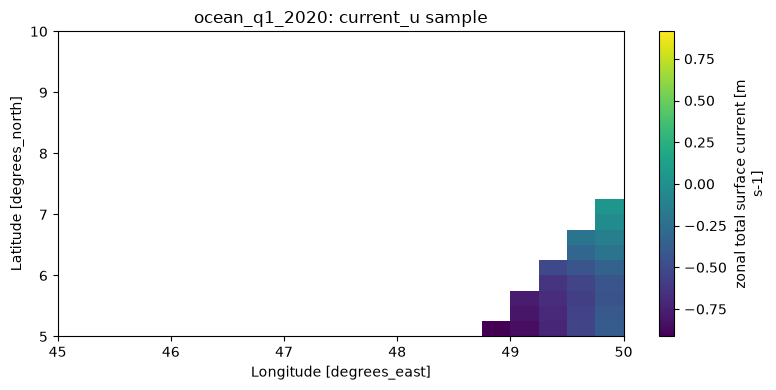

In [4]:
import matplotlib.pyplot as plt

if sample.ndim == 2:
    sample.plot(cmap='viridis', figsize=(8, 4))
    plt.title(f'{STORE_NAME}: {VARIABLE_NAME} sample')
    plt.tight_layout()
    plt.show()
else:
    print('Choose a variable with a two-dimensional sample to plot.')

In [5]:
ocean = datasets["ocean_q1_2020"]
nan_count = int(ocean["current_u"].isnull().sum().compute().item())
print(nan_count, "of", ocean["current_u"].size)

1186276 of 2184000


In [4]:
ocean = datasets["ocean_q1_2020"]
total_nan_count = []
for column in  ocean:
    nan_count = int(ocean[column].isnull().sum().compute().item())
    print(nan_count, "of", ocean[column].size)

1186276 of 2184000
1186276 of 2184000
1056237 of 2184000
1120301 of 2184000
1104467 of 2184000
18901792 of 32760000
0 of 2184000
0 of 2184000


In [6]:
for store_name in ["surface_2020Q1", "thetao_2020Q1"]:
    ds = datasets[store_name]
    print(f"\n{store_name}")

    for variable_name, variable in ds.data_vars.items():
        nan_count = int(variable.isnull().sum().compute().item())
        print(
            f"{variable_name}: "
            f"{nan_count:,} NaNs / {variable.size:,} cells; "
            f"{variable.size - nan_count:,} non-NaN"
        )


surface_2020Q1
current_u: 1,186,276 NaNs / 2,184,000 cells; 997,724 non-NaN
current_v: 1,186,276 NaNs / 2,184,000 cells; 997,724 non-NaN
sla: 1,056,237 NaNs / 2,184,000 cells; 1,127,763 non-NaN
sss: 1,120,301 NaNs / 2,184,000 cells; 1,063,699 non-NaN
sst: 1,104,467 NaNs / 2,184,000 cells; 1,079,533 non-NaN
wind_u: 0 NaNs / 2,184,000 cells; 2,184,000 non-NaN
wind_v: 0 NaNs / 2,184,000 cells; 2,184,000 non-NaN

thetao_2020Q1
thetao: 18,901,792 NaNs / 32,760,000 cells; 13,858,208 non-NaN
